# Capítulo 7 — Formulação Diferencial e Equações de Navier-Stokes

**Autor:** Jader Lugon Junior  
**Livro:** Fenômenos de Transporte: Fundamentos e Modelagem Computacional (Volume I)  

---

## 🎯 Objetivos de Aprendizagem

Ao final deste notebook, você será capaz de:
1. Compreender o balanço de quantidade de movimento e a lei constitutiva de Navier-Stokes.
2. Demonstrar o limite de fluido ideal (Equação de Euler) e a perda da condição de não-deslizamento.
3. Derivar computacionalmente as equações de Saint-Venant a partir de Euler (águas rasas).
4. Verificar a Lei de Hagen-Poiseuille via simplificação de Navier-Stokes em coordenadas cilíndricas.
5. Entender a Lei de Darcy como uma média volumétrica de Navier-Stokes no Volume Elementar Representativo (VER).
6. Comparar numericamente os regimes de Darcy, Forchheimer, Brinkman e Turbulento (Ergun), identificando onde convergem e onde divergem.

In [1]:
# ============================================================
# CONFIGURAÇÃO INICIAL E BIBLIOTECAS
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_banded

# Configuração de estilo dos gráficos para padrão acadêmico
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14

print("✅ Ambiente configurado com sucesso!")
print(f"📦 NumPy {np.__version__} | Matplotlib pronto para visualização.")

C:\Users\jlugo\AppData\Local\Temp\ipykernel_30120\3988927065.py:6: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 2.5.2)
  from scipy.linalg import solve_banded


✅ Ambiente configurado com sucesso!
📦 NumPy 2.5.2 | Matplotlib pronto para visualização.


---

## 7.1 e 7.2 | A Equação Mãe: Balanço de Quantidade de Movimento e Navier-Stokes

A forma diferencial da conservação de quantidade de movimento é:
$$
\frac{\partial (\rho \mathbf{u})}{\partial t} + \nabla \cdot (\rho \mathbf{u} \mathbf{u}) = \mathbf{f}_v + \nabla \cdot \boldsymbol{\sigma}
$$
onde $\boldsymbol{\sigma} = -p \mathbf{I} + \boldsymbol{\tau}$ é o tensor de tensões totais.

Para fluidos newtonianos, com a hipótese de Stokes ($\lambda = -\frac{2}{3}\mu$), obtemos a famosa **Equação de Navier-Stokes**:
$$
\rho \left( \frac{\partial \mathbf{u}}{\partial t} + (\mathbf{u} \cdot \nabla) \mathbf{u} \right) = -\nabla p + \mu \nabla^2 \mathbf{u} + \rho \mathbf{g}
$$

### Exercício 7.1: Verificação do Balanço em Escoamento 1D
Vamos verificar numericamente que, para um escoamento permanente, unidimensional e totalmente desenvolvido entre placas, os termos de inércia se anulam, restando apenas o equilíbrio entre gradiente de pressão e viscosidade.

VERIFICAÇÃO DO BALANÇO DE QUANTIDADE DE MOVIMENTO (1D)

📊 Avaliação dos termos no centro do canal (y = h/2):
  • Termo Inercial (ρ u ∂u/∂x) = 0.00e+00 Pa/m
  • Termo de Pressão (-∂p/∂x)       = 5.00e+03 Pa/m
  • Termo Viscoso (μ ∂²u/∂y²)      = -5.00e+03 Pa/m
  • Resíduo (Pressão + Viscoso)  = -1.68e-10 Pa/m (deve ser ~0)


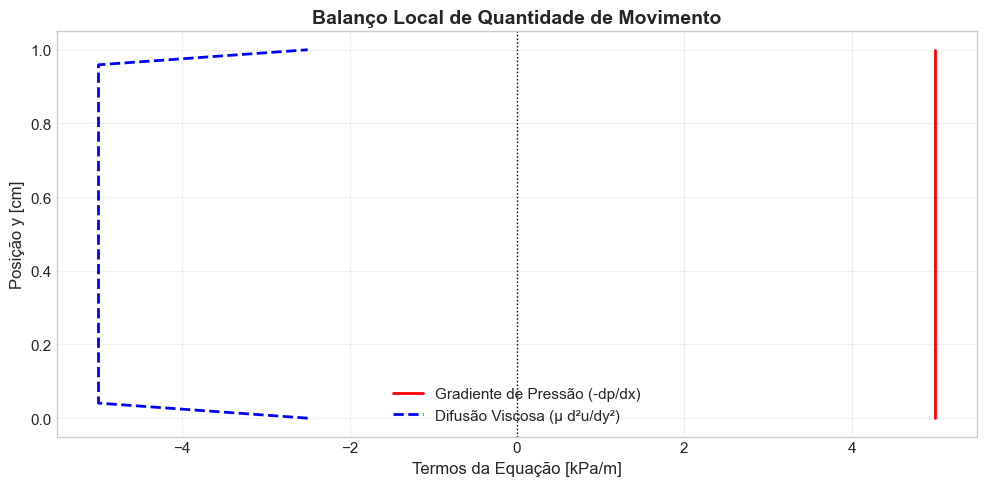


💡 Conclusão: Em escoamento laminar totalmente desenvolvido, a força de pressão é exatamente equilibrada pela força viscosa em todo o domínio.


In [2]:
# ============================================================
# EXERCÍCIO 7.1: Balanço de Termos em Navier-Stokes 1D
# ============================================================
print("=" * 70)
print("VERIFICAÇÃO DO BALANÇO DE QUANTIDADE DE MOVIMENTO (1D)")
print("=" * 70)

# Parâmetros
h = 0.01          # distância entre placas [m]
mu = 1.0e-3       # viscosidade dinâmica [Pa·s]
dp_dx = -5000.0   # gradiente de pressão [Pa/m]
y = np.linspace(0, h, 50)

# Perfil de velocidade de Poiseuille (solução analítica)
u = (1 / (2 * mu)) * dp_dx * (y**2 - h * y)

# Cálculo numérico das derivadas (Diferenças Finitas Centrais)
dy = y[1] - y[0]
du_dy = np.gradient(u, dy)
d2u_dy2 = np.gradient(du_dy, dy)

# Termos da Equação de Navier-Stokes (por unidade de volume)
termo_inercia = np.zeros_like(y)  # u * du/dx = 0 (escoamento totalmente desenvolvido)
termo_pressao = -dp_dx * np.ones_like(y)
termo_viscoso = mu * d2u_dy2

print(f"\n📊 Avaliação dos termos no centro do canal (y = h/2):")
idx_centro = len(y) // 2
print(f"  • Termo Inercial (\u03C1 u \u2202u/\u2202x) = {termo_inercia[idx_centro]:.2e} Pa/m")
print(f"  • Termo de Pressão (-\u2202p/\u2202x)       = {termo_pressao[idx_centro]:.2e} Pa/m")
print(f"  • Termo Viscoso (\u03BC \u2202²u/\u2202y²)      = {termo_viscoso[idx_centro]:.2e} Pa/m")
print(f"  • Resíduo (Pressão + Viscoso)  = {termo_pressao[idx_centro] + termo_viscoso[idx_centro]:.2e} Pa/m (deve ser ~0)")

# Plot dos termos ao longo de y
plt.figure(figsize=(10, 5))
plt.plot(termo_pressao * 1e-3, y * 100, 'r-', lw=2, label='Gradiente de Pressão (-dp/dx)')
plt.plot(termo_viscoso * 1e-3, y * 100, 'b--', lw=2, label='Difusão Viscosa (\u03BC d²u/dy²)')
plt.axvline(0, color='k', linestyle=':', lw=1)
plt.xlabel('Termos da Equação [kPa/m]', fontsize=12)
plt.ylabel('Posição y [cm]', fontsize=12)
plt.title('Balanço Local de Quantidade de Movimento', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\n💡 Conclusão: Em escoamento laminar totalmente desenvolvido, a força de pressão é exatamente equilibrada pela força viscosa em todo o domínio.")

---

## 7.3 | O Limite de Fluido Ideal: Equação de Euler

Quando os efeitos viscosos são desprezíveis ($\mu \to 0$ ou $Re \gg 1$), o termo $\mu \nabla^2 \mathbf{u}$ desaparece, restando a **Equação de Euler**:
$$
\rho \left( \frac{\partial \mathbf{u}}{\partial t} + (\mathbf{u} \cdot \nabla) \mathbf{u} \right) = -\nabla p + \rho \mathbf{g}
$$

**Consequência física crítica:** A condição de contorno de não-deslizamento ($u=0$ na parede) **não pode mais ser imposta**. O fluido "desliza" na parede. Vamos visualizar isso comparando o perfil de Euler (plug flow) com o perfil viscoso.

LIMITE DE FLUIDO IDEAL (EULER) vs. FLUIDO VISCOUSO

📊 Comparação de Velocidades:
  • Velocidade máxima (viscoso, no centro) = 62.4936 m/s
  • Velocidade uniforme (Euler, mesma vazão) = 41.6624 m/s
  • Velocidade na parede (viscoso) = -0.0000 m/s (não-deslizamento)
  • Velocidade na parede (Euler)   = 41.6624 m/s (deslizamento permitido!)


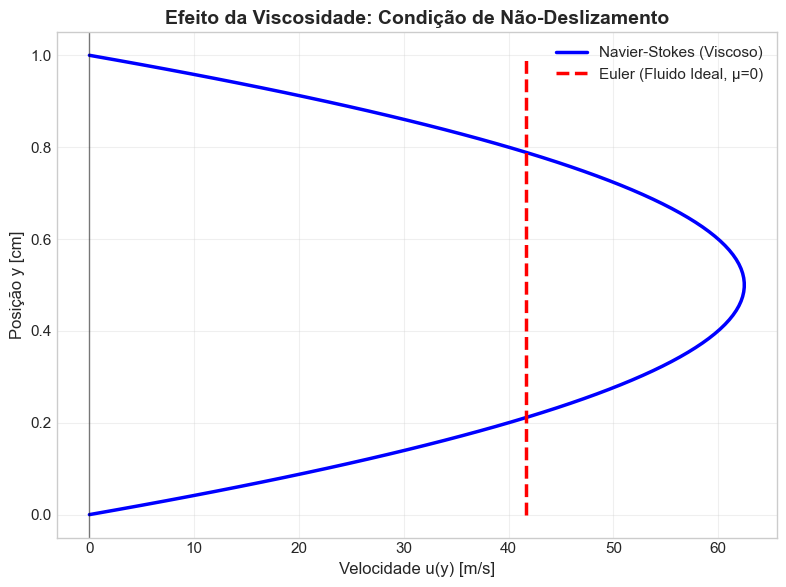


💡 Conclusão: A equação de Euler é uma excelente aproximação no núcleo do escoamento (longe das paredes), mas falha completamente na camada limite, onde os gradientes de velocidade são altos.


In [10]:
# ============================================================
# EXERCÍCIO 7.2: Limite de Euler vs. Perfil Viscoso
# ============================================================
print("=" * 70)
print("LIMITE DE FLUIDO IDEAL (EULER) vs. FLUIDO VISCOUSO")
print("=" * 70)

y_plot = np.linspace(0, h, 100)

# Perfil viscoso (Navier-Stokes / Poiseuille)
u_viscoso = (1 / (2 * mu)) * dp_dx * (y_plot**2 - h * y_plot)

# Perfil de Euler (Fluido Ideal): velocidade uniforme (plug flow)
# Para manter a mesma vazão, a velocidade de Euler seria a velocidade média do perfil viscoso
u_media = np.trapezoid(u_viscoso, y_plot) / h
u_euler = np.full_like(y_plot, u_media)

print(f"\n📊 Comparação de Velocidades:")
print(f"  • Velocidade máxima (viscoso, no centro) = {np.max(u_viscoso):.4f} m/s")
print(f"  • Velocidade uniforme (Euler, mesma vazão) = {u_media:.4f} m/s")
print(f"  • Velocidade na parede (viscoso) = {u_viscoso[0]:.4f} m/s (não-deslizamento)")
print(f"  • Velocidade na parede (Euler)   = {u_euler[0]:.4f} m/s (deslizamento permitido!)")

plt.figure(figsize=(8, 6))
plt.plot(u_viscoso, y_plot * 100, 'b-', lw=2.5, label='Navier-Stokes (Viscoso)')
plt.plot(u_euler, y_plot * 100, 'r--', lw=2.5, label='Euler (Fluido Ideal, \u03BC=0)')
plt.axvline(0, color='k', lw=1, alpha=0.5)
plt.xlabel('Velocidade u(y) [m/s]', fontsize=12)
plt.ylabel('Posição y [cm]', fontsize=12)
plt.title('Efeito da Viscosidade: Condição de Não-Deslizamento', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\n💡 Conclusão: A equação de Euler é uma excelente aproximação no núcleo do escoamento (longe das paredes), mas falha completamente na camada limite, onde os gradientes de velocidade são altos.")

---

## 7.4 | Ponte para Canais Abertos: De Euler a Saint-Venant

As equações de Saint-Venant (águas rasas) são obtidas integrando as equações de Euler (ou Reynolds) na vertical, assumindo:
1. Pressão hidrostática: $p = \rho g (h - z)$
2. Velocidade predominantemente horizontal.
3. Um termo de atrito no fundo ($S_f$) é reintroduzido empiricamente (ex: Manning) para compensar a viscosidade desprezada por Euler.

A equação de momento 1D simplificada em regime permanente torna-se:
$$
\frac{d}{dx}\left(\frac{U^2}{2g} + h\right) = S_0 - S_f
$$
onde $S_0$ é a declividade do fundo e $S_f$ a perda de carga por atrito.

In [5]:
# ============================================================
# EXERCÍCIO 7.3: Conceito de Saint-Venant (Equilíbrio de Forças)
# ============================================================
print("=" * 70)
print("EQUILÍBRIO EM CANAIS ABERTOS (SAINT-VENANT 1D PERMANENTE)")
print("=" * 70)

# Parâmetros de um canal retangular
Q = 5.0         # Vazão [m³/s]
b = 2.0         # Largura do canal [m]
n = 0.015       # Coeficiente de Manning [s/m^(1/3)] (concreto liso)
S0 = 0.001      # Declividade do fundo [m/m]

# Para escoamento uniforme, a profundidade normal (h_n) satisfaz: Q = (A/n) * R^(2/3) * S0^(1/2)
# Vamos encontrar h_n iterativamente (método simples de busca)
h_range = np.linspace(0.1, 3.0, 1000)
A = b * h_range
P = b + 2 * h_range
R = A / P
Q_calc = (A / n) * (R**(2/3)) * (S0**0.5)

# Encontrar o índice mais próximo da vazão alvo
idx = np.argmin(np.abs(Q_calc - Q))
h_n = h_range[idx]
A_n = A[idx]
U_n = Q / A_n

print(f"\n📊 Resultados do Escoamento Uniforme (Saint-Venant):")
print(f"  • Profundidade normal (h_n) = {h_n:.3f} m")
print(f"  • Área molhada (A)          = {A_n:.3f} m²")
print(f"  • Velocidade média (U)      = {U_n:.3f} m/s")
print(f"  • Número de Froude (Fr)     = {U_n / np.sqrt(9.81 * h_n):.3f} ", end="")
if U_n / np.sqrt(9.81 * h_n) < 1:
    print("(Escoamento Subcrítico / Fluvial)")
else:
    print("(Escoamento Supercrítico / Torrencial)")

print("\n💡 Conclusão: A equação de Saint-Venant reintroduz o atrito (via Manning) que a equação de Euler pura ignoraria, permitindo modelar a perda de energia em canais abertos de forma prática.")

EQUILÍBRIO EM CANAIS ABERTOS (SAINT-VENANT 1D PERMANENTE)

📊 Resultados do Escoamento Uniforme (Saint-Venant):
  • Profundidade normal (h_n) = 1.630 m
  • Área molhada (A)          = 3.260 m²
  • Velocidade média (U)      = 1.534 m/s
  • Número de Froude (Fr)     = 0.384 (Escoamento Subcrítico / Fluvial)

💡 Conclusão: A equação de Saint-Venant reintroduz o atrito (via Manning) que a equação de Euler pura ignoraria, permitindo modelar a perda de energia em canais abertos de forma prática.


---

## 7.5 | Verificação Analítica: Hagen-Poiseuille via Navier-Stokes

Aplicando Navier-Stokes em coordenadas cilíndricas $(r, \theta, z)$ para escoamento laminar, permanente, axial e totalmente desenvolvido em um tubo de raio $R$:

A equação se reduz a uma EDO simples:
$$
\frac{1}{r} \frac{d}{dr} \left( r \frac{du_z}{dr} \right) = \frac{1}{\mu} \frac{dp}{dz}
$$

Integrando duas vezes e aplicando as condições de contorno:
1. $u_z(R) = 0$ (não-deslizamento na parede)
2. $\frac{du_z}{dr}(0) = 0$ (simetria no centro)

Obtemos o perfil parabólico de **Hagen-Poiseuille**:
$$
u_z(r) = \frac{1}{4\mu}\left(-\frac{dp}{dz}\right)(R^2 - r^2)
$$

LEI DE HAGEN-POISEUILLE (COORDENADAS CILÍNDRICAS)

📊 Resultados:
  • Velocidade máxima (centro, r=0) = 156.2500 m/s
  • Velocidade média                = 78.1170 m/s
  • Razão u_max / u_medio           = 2.00 (Teórico: 2.00)
  • Vazão volumétrica Q             = 153.38 L/s


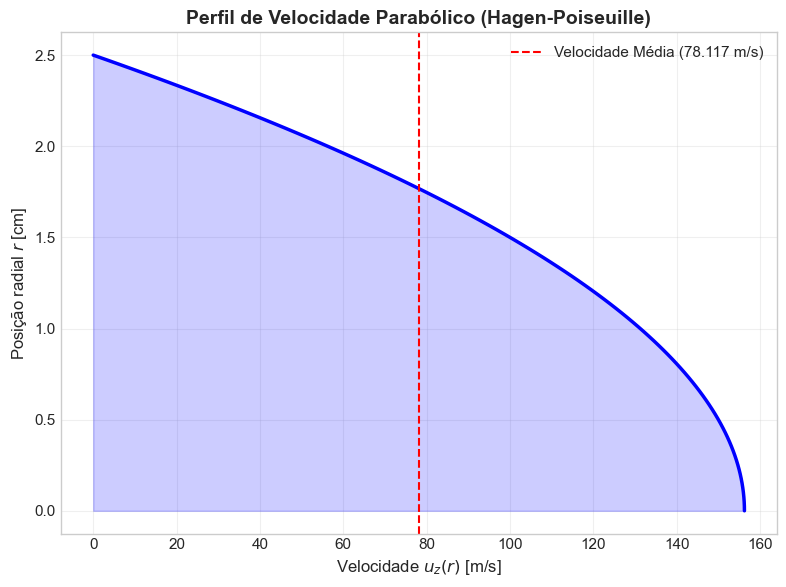

In [11]:
# ============================================================
# EXERCÍCIO 7.4: Perfil de Hagen-Poiseuille
# ============================================================
R_tubo = 0.025      # Raio de 2.5 cm
dp_dz = -1000.0     # Gradiente de pressão [Pa/m]
r = np.linspace(0, R_tubo, 100)

# Solução analítica
u_z = (1 / (4 * mu)) * (-dp_dz) * (R_tubo**2 - r**2)
u_max = u_z[0]
u_medio = np.trapezoid(u_z * 2 * np.pi * r, r) / (np.pi * R_tubo**2)
Q_tubo = np.pi * R_tubo**2 * u_medio

print("=" * 70)
print("LEI DE HAGEN-POISEUILLE (COORDENADAS CILÍNDRICAS)")
print("=" * 70)
print(f"\n📊 Resultados:")
print(f"  • Velocidade máxima (centro, r=0) = {u_max:.4f} m/s")
print(f"  • Velocidade média                = {u_medio:.4f} m/s")
print(f"  • Razão u_max / u_medio           = {u_max / u_medio:.2f} (Teórico: 2.00)")
print(f"  • Vazão volumétrica Q             = {Q_tubo * 1000:.2f} L/s")

plt.figure(figsize=(8, 6))
plt.plot(u_z, r * 100, 'b-', lw=2.5)
plt.fill_betweenx(r * 100, u_z, color='blue', alpha=0.2)
plt.axvline(u_medio, color='r', linestyle='--', lw=1.5, label=f'Velocidade Média ({u_medio:.3f} m/s)')
plt.xlabel('Velocidade $u_z(r)$ [m/s]', fontsize=12)
plt.ylabel('Posição radial $r$ [cm]', fontsize=12)
plt.title('Perfil de Velocidade Parabólico (Hagen-Poiseuille)', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---

## 7.6 | Da Equação de Navier-Stokes à Lei de Darcy

A Lei de Darcy não é uma lei fundamental, mas sim o resultado da **média volumétrica** da equação de Navier-Stokes sobre um Volume Elementar Representativo (VER) de um meio poroso, sob a condição de que o número de Reynolds de grão seja muito baixo ($Re_g \ll 1$).

Nessa condição, os termos inerciais são desprezíveis e o equilíbrio é puramente entre o gradiente de pressão e o arrasto viscoso nas paredes dos poros:
$$
\mathbf{q} = -\frac{k}{\mu} \nabla p = -K \nabla h
$$
onde $\mathbf{q}$ é a velocidade de Darcy (vazão por área total), $k$ é a permeabilidade intrínseca e $K$ é a condutividade hidráulica.

In [12]:
# ============================================================
# EXERCÍCIO 7.5: Cálculo de Parâmetros de Darcy (Kozeny-Carman)
# ============================================================
print("=" * 70)
print("EMERGÊNCIA DA LEI DE DARCY A PARTIR DE PARÂMETROS DO MEIO")
print("=" * 70)

eta = 0.35        # Porosidade [-]
dp = 1.0e-3       # Diâmetro médio do grão [m] (areia fina)
rho_w = 1000.0    # Densidade da água [kg/m³]
g = 9.81          # Gravidade [m/s²]

# Permeabilidade intrínseca pela equação de Kozeny-Carman
k_KC = (eta**3 * dp**2) / (180 * (1 - eta)**2)

# Condutividade hidráulica
K_h = k_KC * rho_w * g / mu

print(f"\n📊 Propriedades do Meio Poroso (Areia Fina):")
print(f"  • Porosidade (\u03B7)               = {eta}")
print(f"  • Diâmetro do grão (dp)         = {dp * 1e3:.1f} mm")
print(f"  • Permeabilidade intrínseca (k) = {k_KC:.3e} m²")
print(f"  • Condutividade hidráulica (K)  = {K_h:.3e} m/s  ({K_h * 86400:.2f} m/dia)")

# Simulação simples de fluxo 1D
L = 10.0          # Comprimento do domínio [m]
dh = 2.0          # Diferença de carga hidráulica [m]
q_Darcy = K_h * (dh / L)

print(f"\n💧 Simulação de Fluxo 1D:")
print(f"  • Gradiente hidráulico (dh/L)   = {dh/L:.4f}")
print(f"  • Velocidade de Darcy (q)       = {q_Darcy:.3e} m/s")
print(f"  • Velocidade real nos poros (v) = {q_Darcy / eta:.3e} m/s")

print("\n💡 Conclusão: A Lei de Darcy é linear porque, em baixas velocidades, a força de arrasto viscoso é diretamente proporcional à velocidade (hipótese de Stokes aplicada ao nível do poro).")

EMERGÊNCIA DA LEI DE DARCY A PARTIR DE PARÂMETROS DO MEIO

📊 Propriedades do Meio Poroso (Areia Fina):
  • Porosidade (η)               = 0.35
  • Diâmetro do grão (dp)         = 1.0 mm
  • Permeabilidade intrínseca (k) = 5.638e-10 m²
  • Condutividade hidráulica (K)  = 5.531e-03 m/s  (477.85 m/dia)

💧 Simulação de Fluxo 1D:
  • Gradiente hidráulico (dh/L)   = 0.2000
  • Velocidade de Darcy (q)       = 1.106e-03 m/s
  • Velocidade real nos poros (v) = 3.160e-03 m/s

💡 Conclusão: A Lei de Darcy é linear porque, em baixas velocidades, a força de arrasto viscoso é diretamente proporcional à velocidade (hipótese de Stokes aplicada ao nível do poro).


---

## 7.7 | Limites de Validade e Extensões: A Hierarquia Completa

Quando a hipótese de $Re_g \ll 1$ deixa de ser válida, ou quando estamos próximos a uma parede, a Lei de Darcy pura falha. Precisamos estender o modelo:

1. **Forchheimer**: Adiciona um termo inercial quadrático para $1 < Re_g < 100$.
2. **Brinkman**: Adiciona um termo de difusão viscosa ($\mu_{eff} \nabla^2 \mathbf{q}$) para capturar a camada limite próxima a paredes ou fraturas.
3. **Ergun (Turbulento)**: Correlação empírica completa que une o regime viscoso (termo de Kozeny-Carman) e o regime inercial/turbulento para $Re_g > 100$.

Vamos comparar numericamente esses 4 modelos no mesmo problema físico.

HIERARQUIA DE MODELOS: COMPARAÇÃO NUMÉRICA


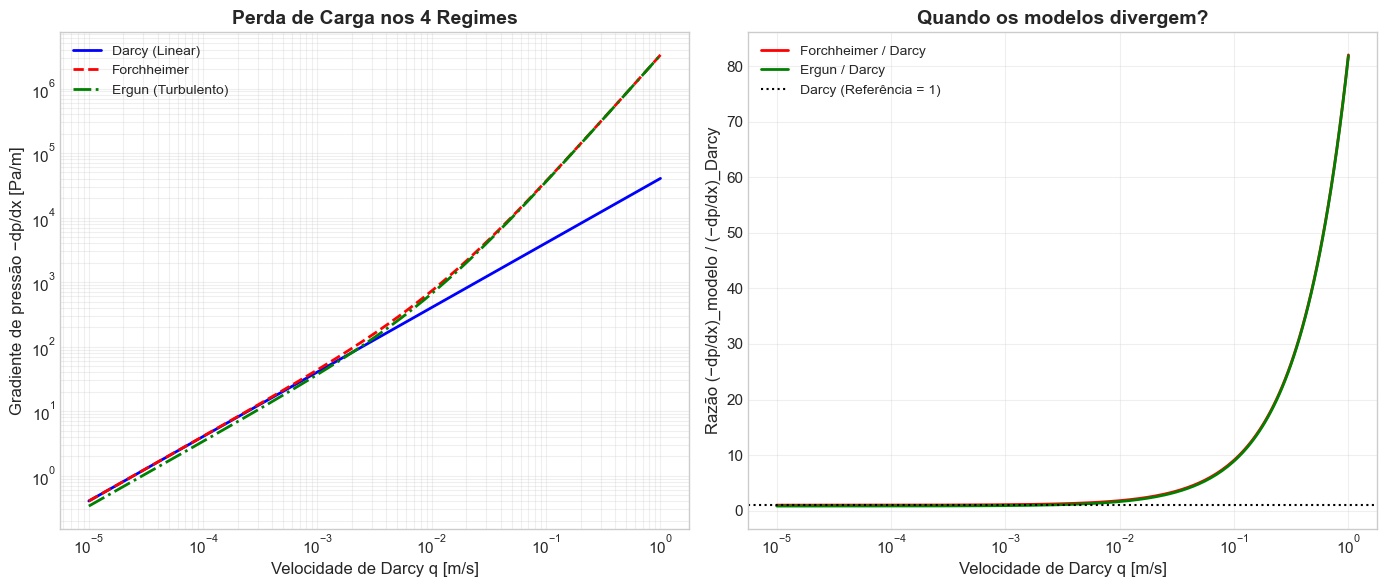


📊 Análise em 3 velocidades representativas:
   q [m/s] |     Re_g |      Darcy |     Forch. |      Ergun |    F/D |    E/D
---------------------------------------------------------------------------
   1.0e-04 |     0.83 |   4.05e+00 |   4.08e+00 |   3.41e+00 |   1.01 |   0.84
   1.0e-02 |    83.33 |   4.05e+02 |   7.33e+02 |   6.66e+02 |   1.81 |   1.64
   1.0e-01 |   833.33 |   4.05e+03 |   3.69e+04 |   3.62e+04 |   9.10 |   8.94

💡 Conclusão: Em baixas velocidades, todos convergem para Darcy. Em altas velocidades, o termo inercial domina, e usar Darcy subestima a perda de carga em ordens de grandeza.


In [13]:
# ============================================================
# EXERCÍCIO 7.6: Comparação dos 4 Regimes (Darcy, Forchheimer, Brinkman, Ergun)
# ============================================================
print("=" * 70)
print("HIERARQUIA DE MODELOS: COMPARAÇÃO NUMÉRICA")
print("=" * 70)

# Parâmetros (Cascalho fino para ampliar a faixa de Re_g)
eta_p = 0.40
dp_p = 5.0e-3     # 5 mm
k_p = (eta_p**3 * dp_p**2) / (180 * (1 - eta_p)**2)
beta_F = 1.75 * (1 - eta_p) / (eta_p**3 * dp_p)  # Coef. Forchheimer

def grad_Darcy(q):
    return (mu / k_p) * q

def grad_Forchheimer(q):
    return (mu / k_p) * q + beta_F * rho_w * np.abs(q) * q

def grad_Ergun(q):
    termo_visc = 150 * (1 - eta_p)**2 / eta_p**3 * mu / dp_p**2 * q
    termo_inerc = 1.75 * (1 - eta_p) / eta_p**3 * rho_w / dp_p * np.abs(q) * q
    return termo_visc + termo_inerc

# Faixa de velocidades de Darcy
q_range = np.logspace(-5, 0, 200)  # de 10 µm/s a 1 m/s
Re_g_range = rho_w * q_range * dp_p / (mu * (1 - eta_p))

gd = grad_Darcy(q_range)
gf = grad_Forchheimer(q_range)
ge = grad_Ergun(q_range)

# Gráfico 1: Perda de carga vs Velocidade
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.loglog(q_range, gd, 'b-', lw=2, label='Darcy (Linear)')
ax1.loglog(q_range, gf, 'r--', lw=2, label='Forchheimer')
ax1.loglog(q_range, ge, 'g-.', lw=2, label='Ergun (Turbulento)')
ax1.set_xlabel('Velocidade de Darcy q [m/s]', fontsize=12)
ax1.set_ylabel('Gradiente de pressão −dp/dx [Pa/m]', fontsize=12)
ax1.set_title('Perda de Carga nos 4 Regimes', fontsize=14, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, which='both', alpha=0.3)

# Gráfico 2: Razão em relação a Darcy
ax2.semilogx(q_range, gf / gd, 'r-', lw=2, label='Forchheimer / Darcy')
ax2.semilogx(q_range, ge / gd, 'g-', lw=2, label='Ergun / Darcy')
ax2.axhline(1.0, color='k', ls=':', lw=1.5, label='Darcy (Referência = 1)')
ax2.set_xlabel('Velocidade de Darcy q [m/s]', fontsize=12)
ax2.set_ylabel('Razão (−dp/dx)_modelo / (−dp/dx)_Darcy', fontsize=12)
ax2.set_title('Quando os modelos divergem?', fontsize=14, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Análise em 3 pontos
print("\n📊 Análise em 3 velocidades representativas:")
print(f"{'q [m/s]':>10} | {'Re_g':>8} | {'Darcy':>10} | {'Forch.':>10} | {'Ergun':>10} | {'F/D':>6} | {'E/D':>6}")
print("-" * 75)
for qi in [1e-4, 1e-2, 1e-1]:
    Rei = rho_w * qi * dp_p / (mu * (1 - eta_p))
    print(f"{qi:10.1e} | {Rei:8.2f} | {grad_Darcy(qi):10.2e} | {grad_Forchheimer(qi):10.2e} | {grad_Ergun(qi):10.2e} | {grad_Forchheimer(qi)/grad_Darcy(qi):6.2f} | {grad_Ergun(qi)/grad_Darcy(qi):6.2f}")

print("\n💡 Conclusão: Em baixas velocidades, todos convergem para Darcy. Em altas velocidades, o termo inercial domina, e usar Darcy subestima a perda de carga em ordens de grandeza.")

EFEITO BRINKMAN: DIFUSÃO VISCOSA PRÓXIMO A UMA PAREDE

📊 Parâmetros da Camada de Brinkman:
  • Comprimento de penetração (δ) = 0.25 mm
  • Relação δ / dp = 0.05 diâmetros de grão


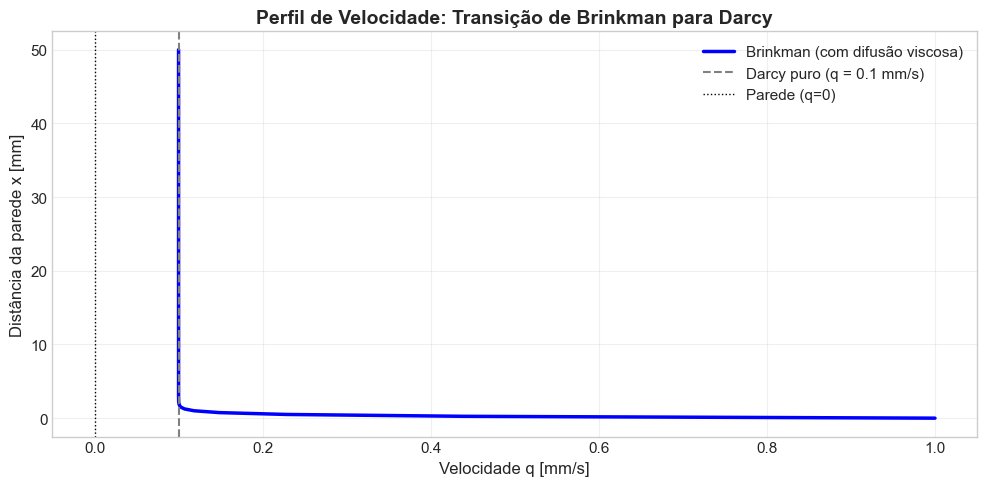


💡 Conclusão: A equação de Brinkman é essencial perto de interfaces (paredes, fraturas). Ela permite satisfazer a condição de não-deslizamento (ou continuidade de tensão), algo que Darcy puro não consegue fazer. Longe da parede (x > 3δ), Brinkman converge suavemente para Darcy.


In [14]:
# ============================================================
# EXERCÍCIO 7.7: O Efeito Brinkman (Camada Limite em Meio Poroso)
# ============================================================
print("=" * 70)
print("EFEITO BRINKMAN: DIFUSÃO VISCOSA PRÓXIMO A UMA PAREDE")
print("=" * 70)

# Domínio: meio poroso ocupando 0 <= x <= L, com parede em x=0
L_dom = 0.05      # 5 cm de domínio
q0 = 1e-3         # velocidade imposta na interface/parede [m/s]
q_inf = 1e-4      # velocidade de Darcy longe da parede [m/s]
N_pts = 200
x = np.linspace(0, L_dom, N_pts)
dx = x[1] - x[0]

# Comprimento de penetração de Brinkman
mu_eff = mu / eta_p
lam = np.sqrt(mu / (k_p * mu_eff))
delta = 1 / lam

print(f"\n📊 Parâmetros da Camada de Brinkman:")
print(f"  • Comprimento de penetração (\u03B4) = {delta * 1e3:.2f} mm")
print(f"  • Relação \u03B4 / dp = {delta / dp_p:.2f} diâmetros de grão")

# Resolução numérica da EDO de Brinkman: d²q/dx² - \u03BB²(q - q_inf) = 0
a = np.ones(N_pts) / dx**2
b = -2 / dx**2 - lam**2 * np.ones(N_pts)
c = np.ones(N_pts) / dx**2
d_vec = -lam**2 * q_inf * np.ones(N_pts)

# Condições de contorno
b[0] = 1; c[0] = 0; d_vec[0] = q0
b[-1] = 1; a[-1] = 0; d_vec[-1] = q_inf

ab = np.zeros((3, N_pts))
ab[0, 1:] = c[:-1]
ab[1, :] = b
ab[2, :-1] = a[1:]

q_brink = solve_banded((1, 1), ab, d_vec)

# Plot
plt.figure(figsize=(10, 5))
plt.plot(q_brink * 1e3, x * 1e3, 'b-', lw=2.5, label='Brinkman (com difusão viscosa)')
plt.axvline(q_inf * 1e3, color='gray', ls='--', lw=1.5, label=f'Darcy puro (q = {q_inf*1e3:.1f} mm/s)')
plt.axvline(0, color='k', ls=':', lw=1, label='Parede (q=0)')
plt.xlabel('Velocidade q [mm/s]', fontsize=12)
plt.ylabel('Distância da parede x [mm]', fontsize=12)
plt.title('Perfil de Velocidade: Transição de Brinkman para Darcy', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\n💡 Conclusão: A equação de Brinkman é essencial perto de interfaces (paredes, fraturas). Ela permite satisfazer a condição de não-deslizamento (ou continuidade de tensão), algo que Darcy puro não consegue fazer. Longe da parede (x > 3\u03B4), Brinkman converge suavemente para Darcy.")

---

## 7.8 | Síntese: Hierarquia Completa de Modelos

| Modelo | Hipótese Principal Desprezada / Adicionada | Domínio de Validade |
|--------|--------------------------------------------|---------------------|
| **Navier-Stokes** | Nenhuma (Equação Mãe) | Todos os regimes newtonianos |
| **Euler** | Viscosidade ($\mu \to 0$) | $Re \gg 1$, longe de paredes |
| **Saint-Venant** | Integração vertical + Pressão hidrostática + Atrito de fundo empírico | Canais abertos e rios (águas rasas) |
| **Hagen-Poiseuille** | Geometria cilíndrica + Escoamento totalmente desenvolvido | Tubos capilares e dutos laminares |
| **Darcy** | Média volumétrica no VER + Inércia desprezível | Meio poroso, $Re_g \ll 1$, longe de interfaces |
| **Forchheimer** | Adiciona inércia quadrática | Meio poroso, $1 < Re_g < 100$ |
| **Brinkman** | Adiciona difusão viscosa ($\nabla^2 \mathbf{q}$) | Meio poroso próximo a paredes/fraturas |
| **Ergun** | Correlação unificada viscosa + inercial | Meio poroso, $Re_g > 100$ (turbulento) |

> 🔍 **Mensagem Central do Capítulo**: A Lei de Darcy (e os outros modelos simplificados) não são leis arbitrárias. Elas são **limites assintóticos** rigorosos da equação de Navier-Stokes. Escolher o modelo errado (ex: usar Darcy em um filtro de alta vazão) pode levar a erros de previsão de perda de carga de **ordens de grandeza**.

---

## 📖 Referências Bibliográficas

- BEAR, J. (1972). *Dynamics of Fluids in Porous Media*. Elsevier.
- BIRD, R. B.; STEWART, W. E.; LIGHTFOOT, E. N. (2002). *Transport Phenomena*. 2ª ed. Wiley.
- CHOW, V. T. (1959). *Open-Channel Hydraulics*. McGraw-Hill.
- WHITE, F. M. (2011). *Fluid Mechanics*. 7ª ed. McGraw-Hill.

---

 <div align="center">

 **QR Code do Capítulo 7**   
 Aponte seu celular para o QR Code no livro físico para acessar este notebook interativo!

 </div>

In [ ]:
print("=" * 70)
print("✅ NOTEBOOK DO CAPÍTULO 7 CONCLUÍDO COM SUCESSO!")
print("=" * 70)
print("\n🎓 Você explorou a hierarquia completa de modelos de transporte.")
print("💡 Dica: Modifique os parâmetros (viscosidade, permeabilidade, vazão)")
print("   nas células acima e observe como os regimes de escoamento mudam!")